In [83]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report
from sklearn.preprocessing import LabelEncoder, MinMaxScaler
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, precision_score, recall_score, f1_score

In [66]:
df_cancer = pd.read_csv("/content/breast-cancer (1).csv")
df_cancer.shape

(569, 32)


Class distribution:
 diagnosis
B    357
M    212
Name: count, dtype: int64


/tmp/ipython-input-1204020314.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=class_counts.index, y=class_counts.values, palette="Set2")


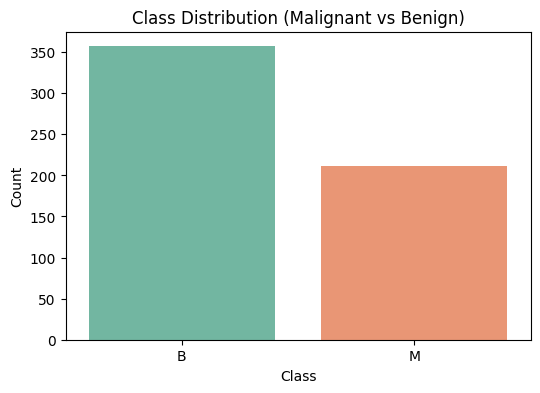

In [67]:
class_counts = df_cancer['diagnosis'].value_counts()
print("\nClass distribution:\n", class_counts)

# Barplot
plt.figure(figsize=(6,4))
sns.barplot(x=class_counts.index, y=class_counts.values, palette="Set2")
plt.title("Class Distribution (Malignant vs Benign)")
plt.xlabel("Class")
plt.ylabel("Count")
plt.show()

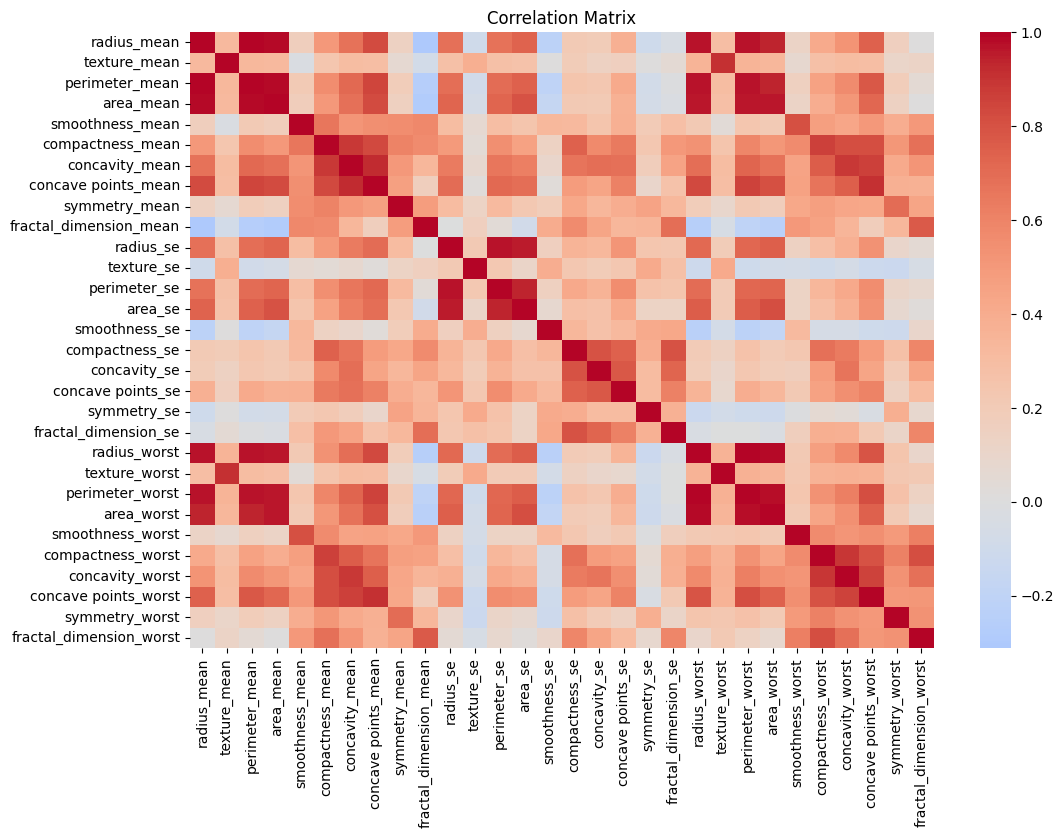

In [68]:
# Step 3: Correlation matrix
corr = df_cancer.drop(columns=['id', 'diagnosis']).corr()  # drop non-numeric columns
plt.figure(figsize=(12,8))
sns.heatmap(corr, cmap="coolwarm", center=0)
plt.title("Correlation Matrix")
plt.show()

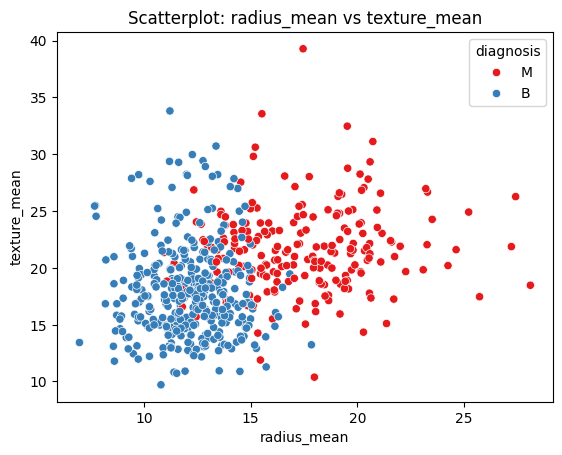

In [69]:
sns.scatterplot(
    data=df_cancer, x="radius_mean", y="texture_mean",
    hue="diagnosis", palette="Set1"
)
plt.title("Scatterplot: radius_mean vs texture_mean")
plt.show()

In [70]:
df_cancer['target'] = df_cancer['diagnosis'].map({'M':1, 'B':0})

# Drop the original 'diagnosis' column before calculating correlation
corr_with_target = df_cancer.drop(columns=['diagnosis']).corr()['target'].abs().sort_values(ascending=False)
top_features = corr_with_target.index[1:11]  # exclude target itself
print("\nTop 10 features most correlated with target:\n", top_features.tolist())


Top 10 features most correlated with target:
 ['concave points_worst', 'perimeter_worst', 'concave points_mean', 'radius_worst', 'perimeter_mean', 'area_worst', 'radius_mean', 'area_mean', 'concavity_mean', 'concavity_worst']


In [71]:
# Step 6: Train-test split using selected features
X = df_cancer[top_features]
y = df_cancer['target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("\nTraining set shape:", X_train.shape)
print("Testing set shape:", X_test.shape)


Training set shape: (455, 10)
Testing set shape: (114, 10)


In [72]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [73]:
kernels = ['linear', 'poly', 'rbf']
models = {}
accuracies = {}

for kernel in kernels:
    svc = SVC(kernel=kernel, degree=3, random_state=42)
    svc.fit(X_train_scaled, y_train)
    y_pred = svc.predict(X_test_scaled)
    models[kernel] = svc
    accuracies[kernel] = accuracy_score(y_test, y_pred)
    print(f"Classification Report for {kernel} kernel:\n")
    print(classification_report(y_test, y_pred))
    print("-"*60)

Classification Report for linear kernel:

              precision    recall  f1-score   support

           0       0.96      1.00      0.98        72
           1       1.00      0.93      0.96        42

    accuracy                           0.97       114
   macro avg       0.98      0.96      0.97       114
weighted avg       0.97      0.97      0.97       114

------------------------------------------------------------
Classification Report for poly kernel:

              precision    recall  f1-score   support

           0       0.84      1.00      0.91        72
           1       1.00      0.67      0.80        42

    accuracy                           0.88       114
   macro avg       0.92      0.83      0.86       114
weighted avg       0.90      0.88      0.87       114

------------------------------------------------------------
Classification Report for rbf kernel:

              precision    recall  f1-score   support

           0       0.94      1.00      0.97     

In [74]:
best_kernel = max(accuracies, key=accuracies.get)
print("Accuracies:", accuracies)
print(f"The best performing kernel is: {best_kernel} with accuracy {accuracies[best_kernel]:.4f}")

Accuracies: {'linear': 0.9736842105263158, 'poly': 0.8771929824561403, 'rbf': 0.956140350877193}
The best performing kernel is: linear with accuracy 0.9737


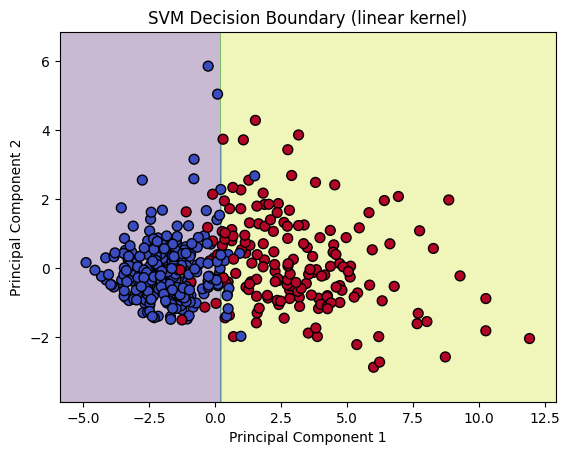

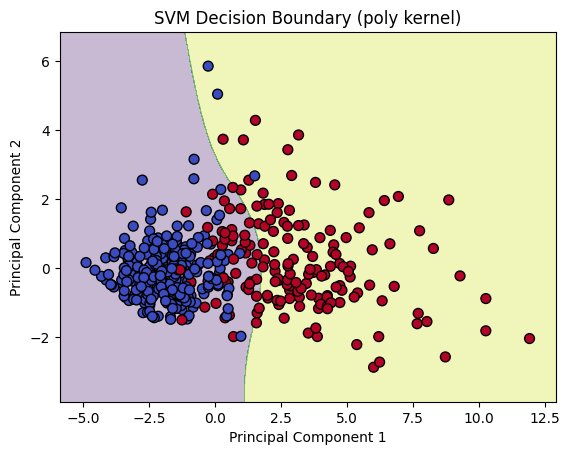

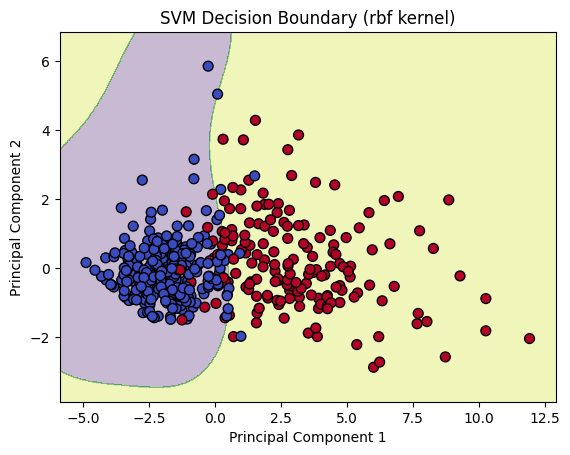

In [75]:
from sklearn.decomposition import PCA

def plot_decision_boundary(X, y, model, title):
    # Reduce dimensions to 2 using PCA
    pca = PCA(n_components=2)
    X_pca = pca.fit_transform(X)

    # Create a mesh grid
    x_min, x_max = X_pca[:, 0].min() - 1, X_pca[:, 0].max() + 1
    y_min, y_max = X_pca[:, 1].min() - 1, X_pca[:, 1].max() + 1
    xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02),
                         np.arange(y_min, y_max, 0.02))

    # Predict over the grid
    # Transform the grid points back to the original feature space before predicting
    Z = model.predict(pca.inverse_transform(np.c_[xx.ravel(), yy.ravel()]))
    Z = Z.reshape(xx.shape)

    plt.contourf(xx, yy, Z, alpha=0.3)
    plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y, s=50, edgecolor='k', cmap=plt.cm.coolwarm)
    plt.xlabel("Principal Component 1")
    plt.ylabel("Principal Component 2")
    plt.title(title)
    plt.show()

# Plot for each kernel
for kernel in kernels:
    plot_decision_boundary(X_train_scaled, y_train, models[kernel], f"SVM Decision Boundary ({kernel} kernel)")

In [76]:
df_titanic = pd.read_csv("/content/Titanic-Dataset.csv")
df_titanic.shape

(891, 12)

In [77]:
features = ['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked']
X = df_titanic[features]
y = df_titanic['Survived']

In [78]:
X = df_titanic[features].copy()  # <- create a copy, not a view
X['Age'] = X['Age'].fillna(X['Age'].median())
X['Embarked'] = X['Embarked'].fillna(X['Embarked'].mode()[0])

In [79]:
X = pd.get_dummies(X, columns=['Sex', 'Embarked'], drop_first=True)

In [80]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [81]:
scaler = MinMaxScaler()
num_features = ['Age', 'SibSp', 'Parch', 'Fare']
X_train[num_features] = scaler.fit_transform(X_train[num_features])
X_test[num_features] = scaler.transform(X_test[num_features])

In [84]:
dt_model = DecisionTreeClassifier(criterion='gini', max_depth=5, random_state=42)
dt_model.fit(X_train, y_train)

DecisionTreeClassifier(max_depth=5, random_state=42)

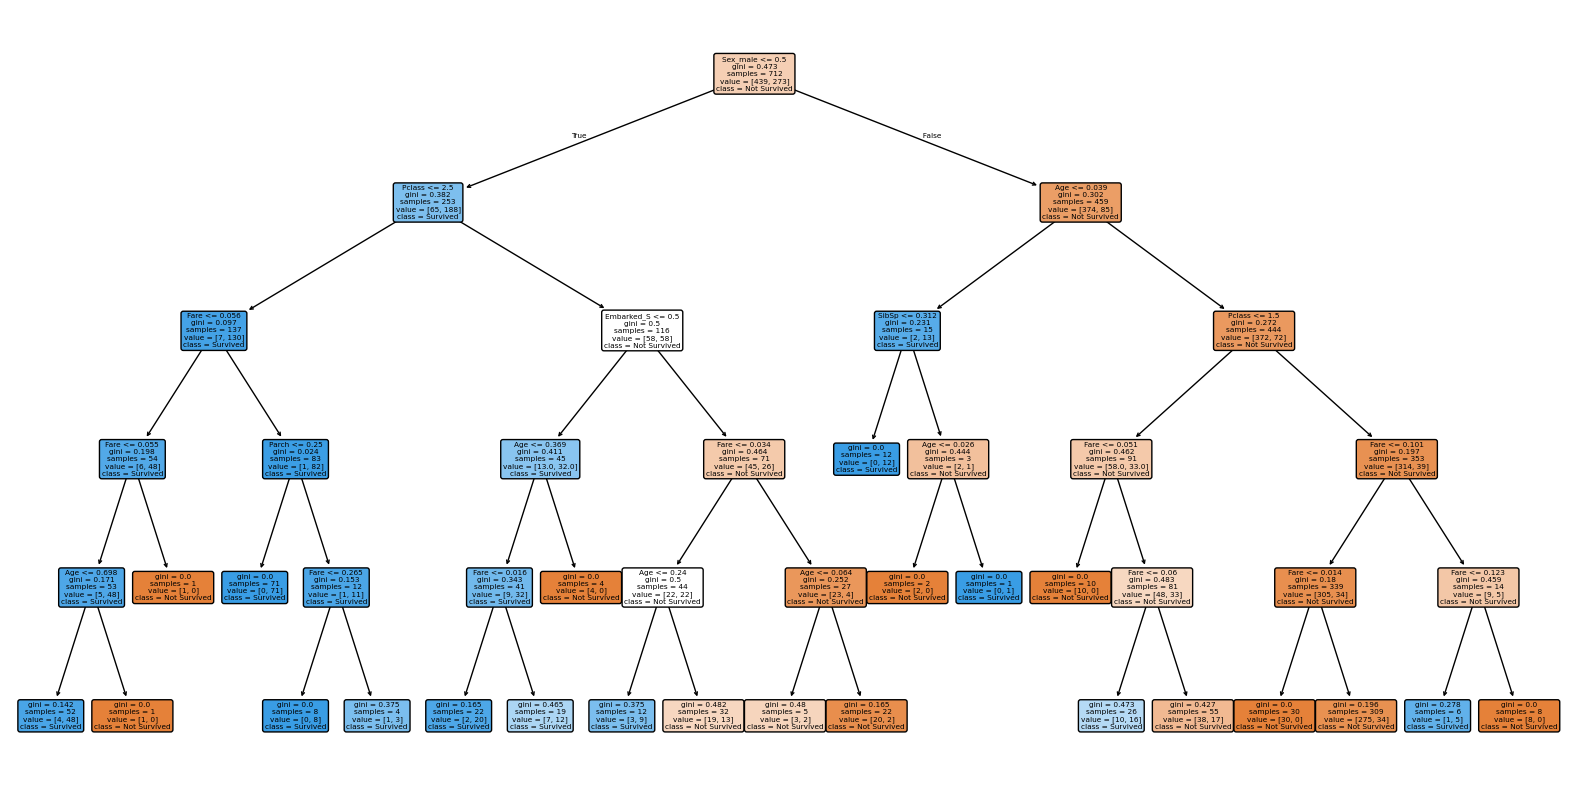

In [85]:
plt.figure(figsize=(20,10))
plot_tree(dt_model, feature_names=X.columns, class_names=['Not Survived', 'Survived'], filled=True, rounded=True)
plt.show()

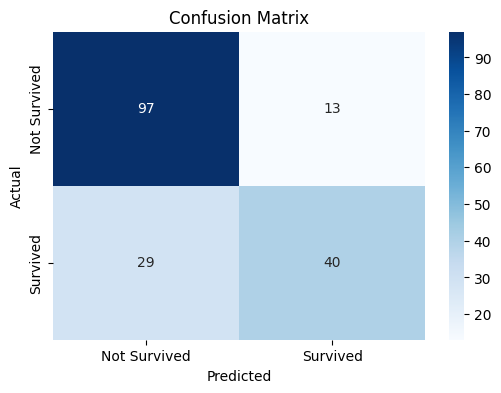

In [86]:
y_pred = dt_model.predict(X_test)
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Not Survived', 'Survived'], yticklabels=['Not Survived', 'Survived'])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

In [87]:
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1-score:", f1_score(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

Accuracy: 0.7653631284916201
Precision: 0.7547169811320755
Recall: 0.5797101449275363
F1-score: 0.6557377049180327

Classification Report:
               precision    recall  f1-score   support

           0       0.77      0.88      0.82       110
           1       0.75      0.58      0.66        69

    accuracy                           0.77       179
   macro avg       0.76      0.73      0.74       179
weighted avg       0.76      0.77      0.76       179

